# 11 — Explainable AI: Explaining the Phase 10 Delivery Models with SHAP

## Purpose
Phase 10 built two checkout-time models:
- a **random forest** that predicts delivery time in days (notebook 08);
- a **logistic regression** that scores late-delivery risk (notebook 09).

Both were **selected on time-series cross-validation**. This notebook explains **why they predict what they predict**, globally and for individual orders. It adds no new model and doesn't redo the evaluation.

## Approach
- **Reconstruction:** the Phase 10 models weren't saved. They are rebuilt from their **recorded configurations** (the same features, preprocessing, development data, hyperparameters and seed), and the rebuilt models must **reproduce the recorded Phase 10 test results exactly** before anything is explained.
- **Explainers:**
  - **Random forest → TreeSHAP** (`shap.TreeExplainer`, exact, `tree_path_dependent`). It uses the trees' own training statistics, so no background data is needed.
  - **Logistic regression → LinearSHAP** (`shap.LinearExplainer`, independent masker). The background is a **500-order sample of development data**, never test data. Explanations are in the model's **log-odds** space.
- **Feature space:** SHAP works on the preprocessed (one-hot) columns. Each categorical's one-hot columns are **summed back into the original 23 checkout-time features**, so the explanations use the Phase 10 feature definitions.
- **Explained population:** a reproducible random sample of **1,000 test-period orders** (2018-05 to 2018-08, seed 42), plus chosen individual orders. Explaining existing predictions on the test period doesn't fit or tune anything.

## Three kinds of "importance" (not interchangeable)
- **Permutation importance (Phase 10):** how much the *test metric* gets worse when a feature is shuffled. It measures dependence for performance and can be shared or understated when features are correlated.
- **SHAP global importance:** the mean |SHAP value|, i.e. how much a feature moves *predictions*, on average, away from the baseline.
- **Local SHAP explanation:** how much each feature pushed *one order's* prediction up or down.

None of these is a causal effect. They describe **the model**, which learned **correlations** in observational data.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.ml.delivery_features import CATEGORICAL, FEATURES, LEAKAGE_COLUMNS, NUMERIC, build_dataset, preprocessor, temporal_split

plt.rcParams.update({"figure.dpi": 110})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
SEED, N_EXPLAIN, N_BACKGROUND = 42, 1000, 500
FIG = ROOT / "reports" / "explainability" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("shap", shap.__version__)

data = build_dataset()
dev, test = temporal_split(data, "2018-05-01")                 # the Phase 10 split
X_dev, X_test = dev[FEATURES], test[FEATURES]
assert not (set(FEATURES) & LEAKAGE_COLUMNS) and dev["purchase_ts"].max() < test["purchase_ts"].min()
print(f"development {len(dev):,} orders | test {len(test):,} orders | {len(FEATURES)} checkout-time features")

shap 0.54.1


development 70,851 orders | test 25,352 orders | 23 checkout-time features


## 1. Reconstruct the Phase 10 models and verify them against the recorded results
The recorded configurations and test results are taken from the executed notebooks 08 and 09. The assertions stop the notebook if a rebuilt model doesn't match.

In [2]:
# recorded Phase 10 configurations (selected on TimeSeriesSplit CV in notebooks 08 / 09)
rf = make_pipeline(preprocessor("onehot"), RandomForestRegressor(n_estimators=200, max_features=0.3, max_depth=20, min_samples_leaf=20,
                                                                 random_state=SEED, n_jobs=-1))
lr = make_pipeline(preprocessor("linear"), LogisticRegression(C=0.01, class_weight="balanced", max_iter=3000))
rf.fit(X_dev, dev["delivery_days"])
lr.fit(X_dev, dev["is_late"])

pred_rf = rf.predict(X_test)
score_lr = lr.predict_proba(X_test)[:, 1]
rebuilt = {"RF test MAE": mean_absolute_error(test["delivery_days"], pred_rf),
           "RF test RMSE": mean_squared_error(test["delivery_days"], pred_rf) ** .5,
           "RF test R2": r2_score(test["delivery_days"], pred_rf),
           "LR test PR-AUC": average_precision_score(test["is_late"], score_lr),
           "LR test ROC-AUC": roc_auc_score(test["is_late"], score_lr)}
recorded = {"RF test MAE": 4.365, "RF test RMSE": 5.923, "RF test R2": 0.193, "LR test PR-AUC": 0.0883, "LR test ROC-AUC": 0.7032}
check = pd.DataFrame({"recorded (Phase 10)": recorded, "rebuilt": rebuilt})
check["match at recorded precision"] = [round(check.loc[k, "rebuilt"], 4 if k.startswith("LR") else 3) == v for k, v in recorded.items()]
display(check)
assert check["match at recorded precision"].all(), "rebuilt models do not reproduce Phase 10 - investigate before explaining"

,recorded (Phase 10),rebuilt,match at recorded precision
RF test MAE,4.3650,4.3651,True
RF test RMSE,5.9230,5.9227,True
RF test R2,0.1930,0.1930,True
LR test PR-AUC,0.0883,0.0883,True
LR test ROC-AUC,0.7032,0.7032,True


**The reconstruction is verified.** Both rebuilt models reproduce the recorded Phase 10 test results at the recorded precision:
- **Random forest:** MAE 4.3651 (recorded 4.365), RMSE 5.9227 (5.923), R² 0.193.
- **Logistic regression:** PR-AUC 0.0883 and ROC-AUC 0.7032.

The models explained below are therefore **the Phase 10 models**: the same configurations, chosen on time-series cross-validation, not on the test set. Nothing was tuned again.

The explained sample (1,000 test orders, seed 42) is representative of the test period: its late rate is 4.30% (4.40% in the full test period) and its median delivery time 8.0 days (7.8).

In [3]:
def original_feature_index(pipeline):
    """Map every preprocessed column to its original checkout-time feature (numeric 1:1, one-hot columns -> their categorical)."""
    pre = pipeline[0]
    names = list(pre.named_transformers_["cat"].get_feature_names_out(CATEGORICAL))
    owner = list(NUMERIC)
    for f in CATEGORICAL:
        n = sum(nm.startswith(f + "_") for nm in names)
        assert n > 0; owner += [f] * n
    assert len(owner) == len(NUMERIC) + len(names) == pre.transform(X_test.head(1)).shape[1]
    return np.array(owner)

def group(values, owner):
    """Sum SHAP values of the one-hot columns of each categorical: (n, n_columns) -> (n, 23) in FEATURES order."""
    return np.column_stack([values[:, owner == f].sum(axis=1) for f in FEATURES])

def display_data(X):
    """Feature values for colouring plots: numeric as is, categoricals as NaN (shown grey)."""
    return X[FEATURES].apply(lambda c: c if c.name in NUMERIC else pd.Series(np.nan, index=c.index)).to_numpy(dtype=float)

def waterfall(expl, title, max_display=8):
    # one full-size SHAP waterfall (shown in the notebook); returns the rendered PNG for the report grid
    import io
    shap.plots.waterfall(expl, max_display=max_display, show=False)
    fig = plt.gcf(); fig.set_size_inches(8, 4.2); plt.title(title, fontsize=10); plt.tight_layout()
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.show()
    return buf.getvalue()

def save_grid(pngs, path, ncols=2):
    # assemble rendered waterfalls into one figure file for the report
    import io
    from PIL import Image
    ims = [Image.open(io.BytesIO(b)).convert("RGB") for b in pngs]
    w, h = max(i.width for i in ims), max(i.height for i in ims)
    grid = Image.new("RGB", (w * ncols, h * -(-len(ims) // ncols)), "white")
    for k, im in enumerate(ims):
        grid.paste(im, ((k % ncols) * w, (k // ncols) * h))
    grid.save(path)

rng = np.random.default_rng(SEED)
sample = test.iloc[np.sort(rng.choice(len(test), N_EXPLAIN, replace=False))]
print(f"explained sample: {len(sample):,} test orders ({sample['purchase_ts'].min():%Y-%m-%d} .. {sample['purchase_ts'].max():%Y-%m-%d}), "
      f"late rate {sample['is_late'].mean():.2%} vs test {test['is_late'].mean():.2%}, median delivery {sample['delivery_days'].median():.1f} vs {test['delivery_days'].median():.1f} days")

explained sample: 1,000 test orders (2018-05-01 .. 2018-08-28), late rate 4.30% vs test 4.40%, median delivery 8.0 vs 7.8 days


## 2. Regression: why does the random forest predict a longer or shorter delivery?

In [4]:
owner_rf = original_feature_index(rf)
Xs_rf = rf[0].transform(sample[FEATURES])
tree_explainer = shap.TreeExplainer(rf[-1])                         # exact TreeSHAP, tree_path_dependent (no background data)
sv_rf = tree_explainer.shap_values(Xs_rf, check_additivity=True)
base_rf = float(np.ravel(tree_explainer.expected_value)[0])

# additivity: base value + sum of SHAP values = the model's own prediction, for every explained order
recon = base_rf + sv_rf.sum(axis=1)
pipe_pred = rf.predict(sample[FEATURES])
print(f"base value (mean training prediction) {base_rf:.3f} days | max |base + sum(SHAP) - prediction| = {np.abs(recon - pipe_pred).max():.2e}")
assert np.allclose(recon, pipe_pred, atol=1e-6)
G_rf = group(sv_rf, owner_rf)
assert np.allclose(G_rf.sum(axis=1), sv_rf.sum(axis=1))             # grouping preserves additivity
expl_rf = shap.Explanation(values=G_rf, base_values=np.full(len(sample), base_rf), data=display_data(sample), feature_names=FEATURES)

base value (mean training prediction) 13.669 days | max |base + sum(SHAP) - prediction| = 2.52e-13


,mean |SHAP| (days),SHAP rank,permutation: MAE increase (Phase 10),permutation rank
same_state,1.7926,1,0.1610,2.0000
purchase_month,1.5317,2,NaN,NaN
promised_days,1.0094,3,0.3430,1.0000
customer_state,0.7511,4,NaN,NaN
distance_km,0.7419,5,0.1520,3.0000
customer_lat,0.5682,6,0.0940,4.0000
items_freight_total,0.2911,7,NaN,NaN
seller_lat,0.2658,8,0.0240,8.0000
customer_lng,0.2389,9,0.0650,5.0000
seller_lng,0.1946,10,0.0570,6.0000


top-10 overlap SHAP vs permutation: 7/10 | Spearman rank correlation on shared features: 0.84


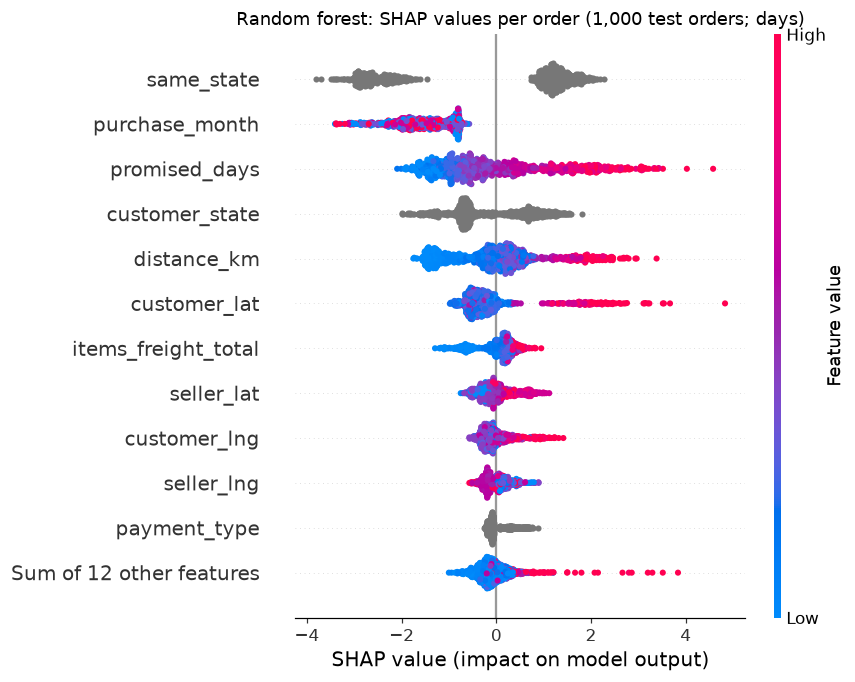

In [5]:
def recorded_permutation(nb_path, metric_col):
    """Top-10 permutation importances as recorded in a Phase 10 notebook output (read-only)."""
    nb = json.load(open(nb_path, encoding="utf-8"))
    txt = next("".join(o["data"]["text/plain"]) for c in nb["cells"] for o in c.get("outputs", [])
               if "text/plain" in o.get("data", {}) and metric_col in "".join(o["data"]["text/plain"]))
    rows = [l.split() for l in txt.splitlines()[1:] if l.split() and l.split()[0] in FEATURES]
    return pd.Series({r[0]: float(r[1]) for r in rows})

perm_rf = recorded_permutation(ROOT / "notebooks" / "08_regression_modeling.ipynb", "MAE increase (days)")
imp_rf = pd.DataFrame({"mean |SHAP| (days)": np.abs(G_rf).mean(axis=0)}, index=FEATURES).sort_values("mean |SHAP| (days)", ascending=False)
imp_rf["SHAP rank"] = range(1, len(imp_rf) + 1)
imp_rf["permutation: MAE increase (Phase 10)"] = perm_rf.reindex(imp_rf.index)
imp_rf["permutation rank"] = imp_rf["permutation: MAE increase (Phase 10)"].rank(ascending=False)
display(imp_rf.head(12))
both = imp_rf.dropna()
print(f"top-10 overlap SHAP vs permutation: {len(set(imp_rf.index[:10]) & set(perm_rf.index))}/10 | "
      f"Spearman rank correlation on shared features: {both['SHAP rank'].corr(both['permutation rank'], method='spearman'):.2f}")

with warnings.catch_warnings():   # categorical features have no numeric colour (NaN, drawn grey): nanquantile warns on all-NaN columns
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    shap.plots.beeswarm(expl_rf, max_display=12, show=False)
plt.title("Random forest: SHAP values per order (1,000 test orders; days)"); plt.tight_layout()
plt.savefig(FIG / "rf_shap_beeswarm.png", bbox_inches="tight"); plt.show()

**Global explanation of the delivery-time model.**
- **Additivity is exact:** for every explained order, base value + Σ SHAP = the forest's prediction (maximum deviation 2.5e-13). The base value, 13.7 days, is the average prediction on the training data; each order's SHAP values move it from there.
- **Largest average influence on predictions (mean |SHAP|):**
  - **whether customer and seller are in the same state:** 1.8 days;
  - **purchase month:** 1.5 days;
  - **the promised delivery time:** 1.0 day;
  - customer state, distance and customer latitude: 0.6–0.75 days each.

  Delivery time is explained by **route geography and the season**, not by what is bought or how it's paid.
- **SHAP and permutation importance broadly agree** (7 of the top 10 shared; Spearman rank correlation 0.84 on shared features), with two instructive differences:
  - **`purchase_month`** is the 2nd-largest SHAP influence but not in the permutation top 10. The forest learned month effects from 2017–early 2018 (slower deliveries around Black Friday and February–March 2018) and uses them strongly, but those effects don't improve accuracy in May–August 2018. **Large attribution doesn't mean useful attribution under drift.**
  - **`customer_state`** ranks 4th in SHAP but is absent from the permutation top 10. It's strongly correlated with the customer coordinates: permuting one of several correlated features costs little accuracy because the others carry the same information, whereas SHAP divides the effect among them.

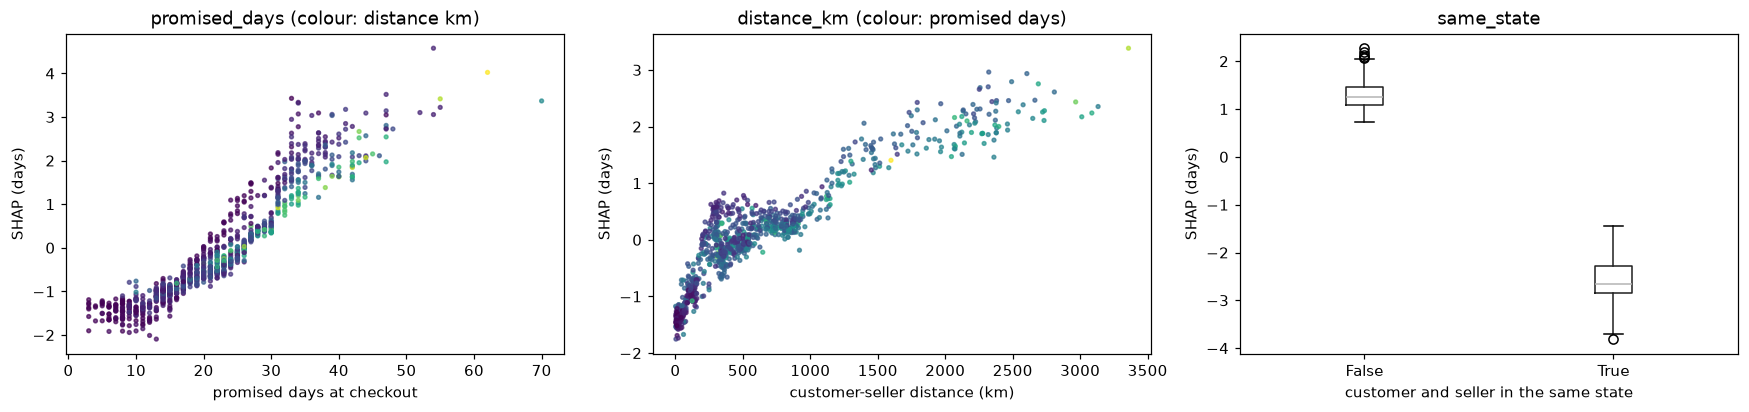

mean SHAP of same_state: {'False': 1.29, 'True': -2.57} | correlation(promised_days, its SHAP): 0.94


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
j = {f: FEATURES.index(f) for f in FEATURES}
ax[0].scatter(sample["promised_days"], G_rf[:, j["promised_days"]], c=sample["distance_km"], cmap="viridis", s=6, alpha=.7)
ax[0].set(title="promised_days (colour: distance km)", xlabel="promised days at checkout", ylabel="SHAP (days)")
ax[1].scatter(sample["distance_km"], G_rf[:, j["distance_km"]], c=sample["promised_days"], cmap="viridis", s=6, alpha=.7)
ax[1].set(title="distance_km (colour: promised days)", xlabel="customer-seller distance (km)", ylabel="SHAP (days)")
ss = pd.DataFrame({"same_state": sample["same_state"].to_numpy(), "SHAP": G_rf[:, j["same_state"]]})
ss.boxplot(column="SHAP", by="same_state", ax=ax[2], grid=False); ax[2].set(title="same_state", xlabel="customer and seller in the same state", ylabel="SHAP (days)")
plt.suptitle(""); plt.tight_layout(); plt.savefig(FIG / "rf_dependence.png", bbox_inches="tight"); plt.show()
print("mean SHAP of same_state:", ss.groupby("same_state")["SHAP"].mean().round(2).to_dict(),
      "| correlation(promised_days, its SHAP):", round(np.corrcoef(sample["promised_days"], G_rf[:, j["promised_days"]])[0, 1], 2))

**Dependence plots:**
- **Promise:** the SHAP value of `promised_days` rises almost monotonically with the promise (correlation 0.94). Olist's promise already encodes route difficulty, and the forest reuses that information.
- **Distance:** it adds days mainly beyond a few hundred kilometres, and the colour shows that long distances usually come with long promises. This is the main **interaction**: the two features carry overlapping route information, and the forest splits their joint effect.
- **Same state:** same-state orders are predicted about **2.6 days faster** than the baseline on average (mean SHAP −2.57), and cross-state orders 1.3 days slower (+1.29). It's the clearest single driver.

All of these are statements about **the model's use of features**. They match the logistics story (local routes are faster), but they don't prove that changing a feature would change delivery time.

### Local explanations: one short and one long predicted delivery
Each waterfall starts at the base value (the average prediction) and adds each feature's contribution to reach the order's prediction. The prediction and the actual delivery time are printed for comparison.

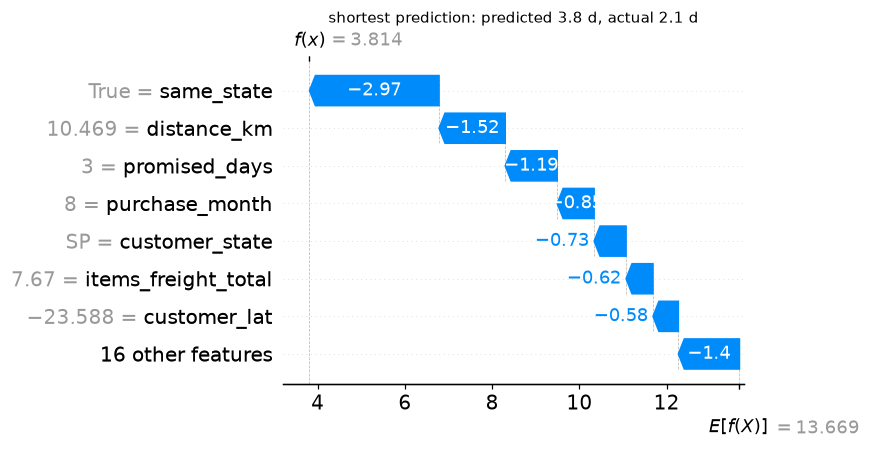

shortest prediction: SP <- SP, 10 km, promised 3 d, main category watches_gifts | predicted 3.8, actual 2.1
   largest contributions (days): {'same_state': -2.97, 'distance_km': -1.52, 'promised_days': -1.19, 'purchase_month': -0.85, 'customer_state': -0.73, 'items_freight_total': -0.62}


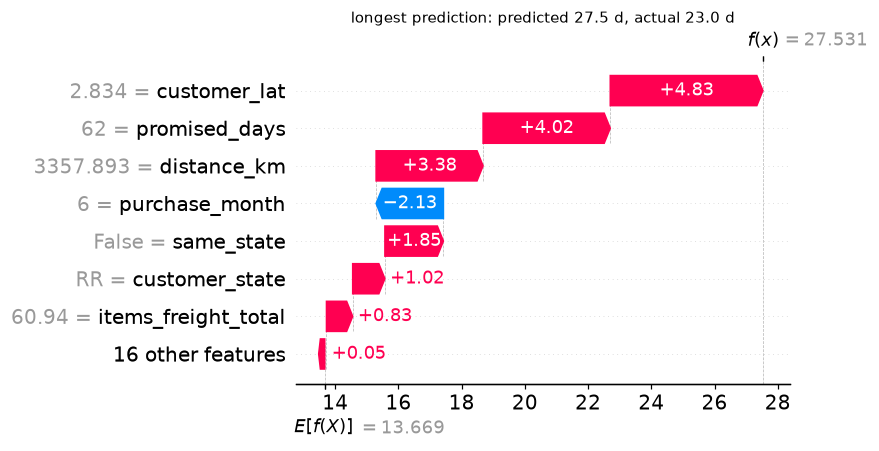

longest prediction: RR <- SP, 3358 km, promised 62 d, main category home_appliances | predicted 27.5, actual 23.0
   largest contributions (days): {'customer_lat': 4.83, 'promised_days': 4.02, 'distance_km': 3.38, 'purchase_month': -2.13, 'same_state': 1.85, 'customer_state': 1.02}


In [7]:
def local_table(G, i, X, top=6):
    s = pd.Series(G[i], index=FEATURES)
    return s.reindex(s.abs().sort_values(ascending=False).index[:top])

fast, slow = int(np.argmin(pipe_pred)), int(np.argmax(pipe_pred))
pngs = []
for k, (i, label) in enumerate(((fast, "shortest prediction"), (slow, "longest prediction"))):
    row = sample.iloc[i]
    e = shap.Explanation(values=G_rf[i], base_values=base_rf, data=sample[FEATURES].iloc[i].to_numpy(dtype=object), feature_names=FEATURES)
    pngs.append(waterfall(e, f"{label}: predicted {pipe_pred[i]:.1f} d, actual {row['delivery_days']:.1f} d"))
    assert np.isclose(base_rf + G_rf[i].sum(), pipe_pred[i])
    print(f"{label}: {row['customer_state']} <- {row['seller_state']}, {row['distance_km']:.0f} km, promised {row['promised_days']:.0f} d, "
          f"main category {row['main_category']} | predicted {pipe_pred[i]:.1f}, actual {row['delivery_days']:.1f}")
    print("   largest contributions (days):", local_table(G_rf, i, sample).round(2).to_dict())
save_grid(pngs, FIG / "rf_waterfalls.png")

**Local explanations.**
- **Shortest prediction (3.8 days; actual 2.1):** a São Paulo → São Paulo order over 10 km with a 3-day promise. The prediction is pulled below the 13.7-day baseline mainly by **same state (−3.0 days)**, **short distance (−1.5)**, **short promise (−1.2)** and the purchase month (−0.9).
- **Longest prediction (27.5 days; actual 23.0):** a São Paulo → Roraima order over 3,358 km with a 62-day promise. It's pushed up by **customer latitude (+4.8 days, the far north)**, **the long promise (+4.0)**, **distance (+3.4)** and **different states (+1.9)**. The month pulls it down slightly (−2.1).

**What this means:** each order's prediction can be explained to an operations analyst in route terms, for example "same state and close: fast" or "far north and a long promise: slow". That's what makes the estimate usable for customer communication.

### Interactions (optional, not computed)
Exact TreeSHAP interaction values cost roughly one extra full SHAP pass per input column: about 100 one-hot columns on a forest of 200 depth-20 trees. That's disproportionate for a laptop. The dependence plots above show the main interaction instead, through colouring: the effect of the promise depends on distance, and vice versa.

## 3. Classification: why does the logistic regression flag an order as at risk of being late?

base value (log-odds at the background mean) -0.283 | max |base + sum(SHAP) - decision_function| = 2.22e-15 | max |SHAP - coef*(x - mean)| = 0.00e+00


,mean |SHAP| (log-odds),SHAP rank,permutation: PR-AUC drop (Phase 10),permutation rank
promised_days,0.6600,1,0.0393,1.0000
same_state,0.3621,2,NaN,NaN
customer_state,0.2938,3,0.0028,4.5000
distance_km,0.2439,4,0.0044,3.0000
seller_state,0.2238,5,0.0028,4.5000
seller_lat,0.0953,6,0.0069,2.0000
seller_lng,0.0886,7,NaN,NaN
main_category,0.0868,8,NaN,NaN
customer_lng,0.0739,9,0.0006,10.0000
items_freight_total,0.0655,10,NaN,NaN


top-10 overlap SHAP vs permutation: 6/10 | Spearman rank correlation on shared features: 0.71


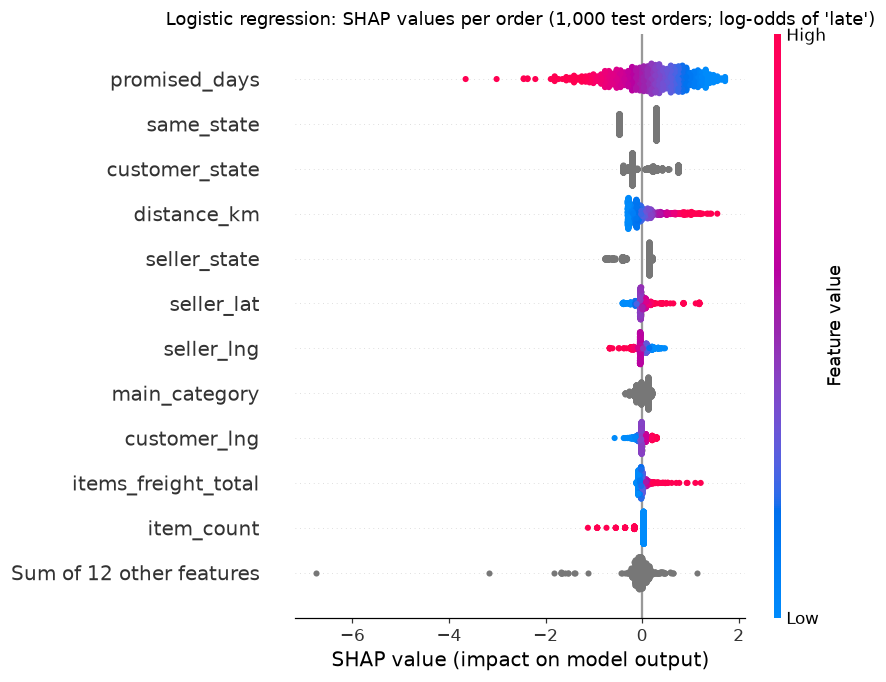

In [8]:
owner_lr = original_feature_index(lr)
background = lr[0].transform(dev[FEATURES].iloc[np.sort(np.random.default_rng(SEED).choice(len(dev), N_BACKGROUND, replace=False))])   # development only
lin_explainer = shap.LinearExplainer(lr[-1], shap.maskers.Independent(background, max_samples=N_BACKGROUND))
Xs_lr = lr[0].transform(sample[FEATURES])
sv_lr = lin_explainer.shap_values(Xs_lr)
base_lr = float(np.ravel(lin_explainer.expected_value)[0])

# checks: (1) additivity against the model's decision function (log-odds); (2) closed form coef * (x - background mean)
logit = lr.decision_function(sample[FEATURES])
closed = lr[-1].coef_[0] * (Xs_lr - background.mean(axis=0))
print(f"base value (log-odds at the background mean) {base_lr:.3f} | max |base + sum(SHAP) - decision_function| = {np.abs(base_lr + sv_lr.sum(axis=1) - logit).max():.2e} | "
      f"max |SHAP - coef*(x - mean)| = {np.abs(sv_lr - closed).max():.2e}")
assert np.allclose(base_lr + sv_lr.sum(axis=1), logit, atol=1e-8) and np.allclose(sv_lr, closed, atol=1e-8)
G_lr = group(sv_lr, owner_lr)
expl_lr = shap.Explanation(values=G_lr, base_values=np.full(len(sample), base_lr), data=display_data(sample), feature_names=FEATURES)

perm_lr = recorded_permutation(ROOT / "notebooks" / "09_classification_modeling.ipynb", "PR-AUC drop")
imp_lr = pd.DataFrame({"mean |SHAP| (log-odds)": np.abs(G_lr).mean(axis=0)}, index=FEATURES).sort_values("mean |SHAP| (log-odds)", ascending=False)
imp_lr["SHAP rank"] = range(1, len(imp_lr) + 1)
imp_lr["permutation: PR-AUC drop (Phase 10)"] = perm_lr.reindex(imp_lr.index)
imp_lr["permutation rank"] = imp_lr["permutation: PR-AUC drop (Phase 10)"].rank(ascending=False)
display(imp_lr.head(12))
both = imp_lr.dropna()
print(f"top-10 overlap SHAP vs permutation: {len(set(imp_lr.index[:10]) & set(perm_lr.index))}/10 | "
      f"Spearman rank correlation on shared features: {both['SHAP rank'].corr(both['permutation rank'], method='spearman'):.2f}")
with warnings.catch_warnings():   # see the random-forest beeswarm: grey categoricals
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    shap.plots.beeswarm(expl_lr, max_display=12, show=False)
plt.title("Logistic regression: SHAP values per order (1,000 test orders; log-odds of 'late')"); plt.tight_layout()
plt.savefig(FIG / "lr_shap_beeswarm.png", bbox_inches="tight"); plt.show()

**Global explanation of the late-risk model (log-odds of "late").**
- **Additivity is exact:** base + Σ SHAP equals the model's decision function (maximum deviation 2.2e-15), and the SHAP values equal the closed form coefficient × (x − background mean) exactly. That is expected, because LinearSHAP with an independent masker is analytic.
- **The base value, −0.28 log-odds,** is the score at the development background mean. Because of `class_weight="balanced"` it isn't the observed late rate: the model's outputs are **risk scores, not calibrated probabilities.**
- **Most influential:**
  - **the promised delivery time** (mean |SHAP| 0.66);
  - **same state** (0.36);
  - **customer state** (0.29), **distance** (0.24) and **seller state** (0.22).
- **SHAP and permutation importance:** 6 of the top 10 are shared, with a Spearman rank correlation of 0.71 on shared features. Permutation (Phase 10) ranks seller latitude 2nd and has no `same_state`. With correlated location features (states, coordinates, same-state, distance), how importance is split between them depends on the method. Neither ranking is "wrong"; they measure different things.

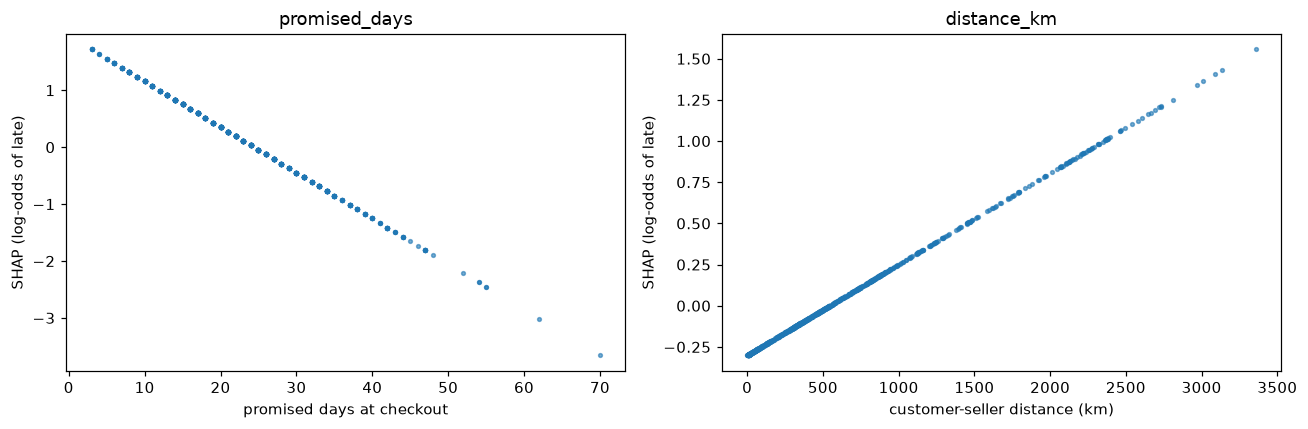

largest standardised numeric coefficients (log-odds per 1 SD): {'promised_days': -0.622, 'distance_km': 0.328, 'distinct_sellers': -0.164, 'seller_lat': 0.145, 'purchase_month': -0.14, 'seller_lng': -0.126}


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(sample["promised_days"], G_lr[:, FEATURES.index("promised_days")], s=6, alpha=.6)
ax[0].set(title="promised_days", xlabel="promised days at checkout", ylabel="SHAP (log-odds of late)")
ax[1].scatter(sample["distance_km"], G_lr[:, FEATURES.index("distance_km")], s=6, alpha=.6)
ax[1].set(title="distance_km", xlabel="customer-seller distance (km)", ylabel="SHAP (log-odds of late)")
plt.tight_layout(); plt.show()
coefs = pd.Series(lr[-1].coef_[0][:len(NUMERIC)], index=NUMERIC).sort_values(key=abs, ascending=False)
print("largest standardised numeric coefficients (log-odds per 1 SD):", coefs.head(6).round(3).to_dict())

**Dependence plots.** For a linear model, each feature's SHAP value is a straight line in the (standardised) feature. The direction comes from the coefficient:
- **Longer promise → lower late risk:** −0.62 log-odds per standard deviation, the largest coefficient. A long promise leaves slack, while a short promise is easy to miss. This is also why the 2018 promise shortening raised scores (Phase 10).
- **Longer distance → higher risk:** +0.33 per SD.
- **Smaller effects:** the number of sellers (−0.16), seller latitude (+0.15) and purchase month (−0.14).

A straight line can't capture thresholds or interactions, and it can extrapolate badly beyond the training range, as the false-positive example below shows.

### Local explanations: true positive, false positive, false negative, true negative
Orders are flagged with the Phase 10 operating policy: the **top 10% of the period's orders by score**, a threshold computed from scores only, without labels. One order of each outcome is taken from the whole test period:
- **TP:** the highest-scoring late order;
- **FP:** the highest-scoring on-time order;
- **FN:** the lowest-scoring late order;
- **TN:** an unflagged on-time order with a median score.

capacity threshold (90th percentile of test scores) 0.717: flagged 10.0%, TP 262, FP 2,274, FN 853, TN 21,963


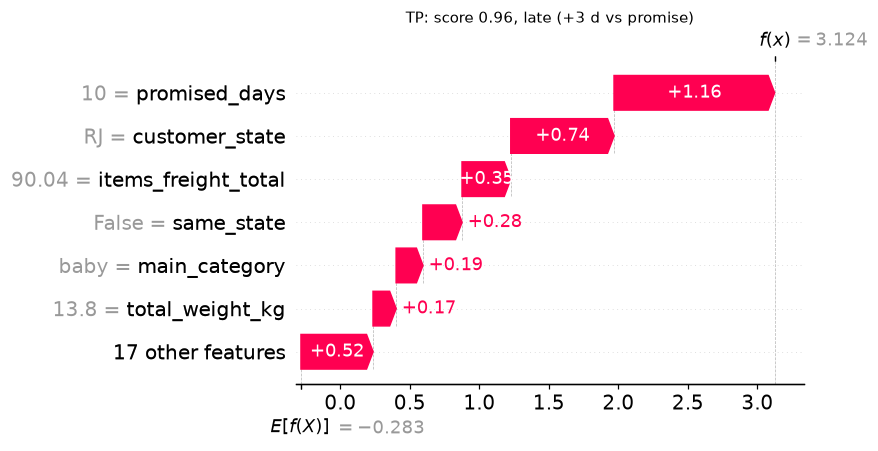

TP: 2018-08-04 RJ <- SP, 625 km, promised 10 d, delivered in 13.5 d, freight 90.04 BRL | score 0.958 (log-odds 3.12)
   largest contributions (log-odds): {'promised_days': 1.16, 'customer_state': 0.74, 'items_freight_total': 0.35, 'same_state': 0.28, 'main_category': 0.19}


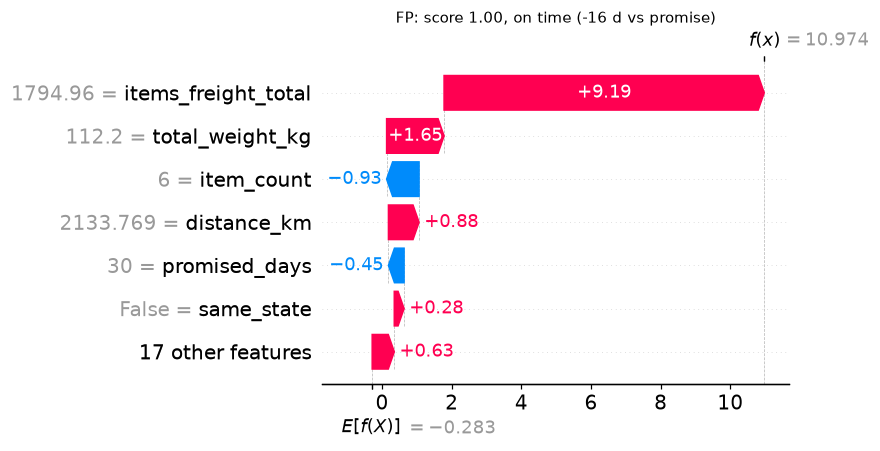

FP: 2018-07-02 PB <- SP, 2134 km, promised 30 d, delivered in 13.8 d, freight 1794.96 BRL | score 1.000 (log-odds 10.97)
   largest contributions (log-odds): {'items_freight_total': 9.19, 'total_weight_kg': 1.65, 'item_count': -0.93, 'distance_km': 0.88, 'promised_days': -0.45}


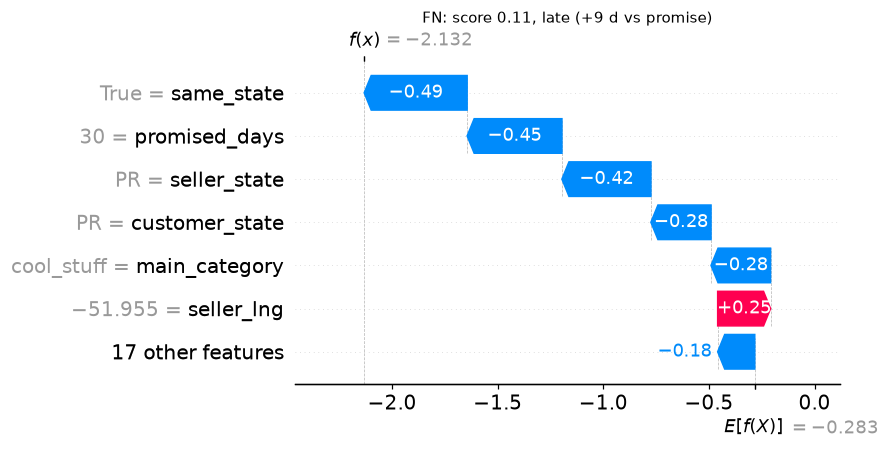

FN: 2018-07-03 PR <- PR, 353 km, promised 30 d, delivered in 38.5 d, freight 14.29 BRL | score 0.106 (log-odds -2.13)
   largest contributions (log-odds): {'same_state': -0.49, 'promised_days': -0.45, 'seller_state': -0.42, 'customer_state': -0.28, 'main_category': -0.28}


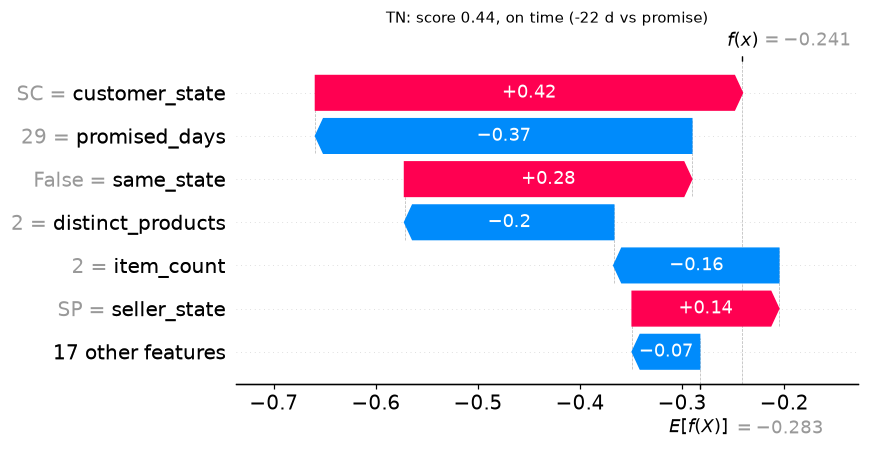

TN: 2018-08-16 SC <- SP, 582 km, promised 29 d, delivered in 7.0 d, freight 37.88 BRL | score 0.440 (log-odds -0.24)
   largest contributions (log-odds): {'customer_state': 0.42, 'promised_days': -0.37, 'same_state': 0.28, 'distinct_products': -0.2, 'item_count': -0.16}
freight context (development): median 16.79, p99 98.98, max 1002.29 BRL | FP freight percentile: 100.00% | LR coefficient of items_freight_total: +0.105 log-odds per SD


In [10]:
th = np.quantile(score_lr, 0.90)
flag, late = score_lr >= th, test["is_late"].to_numpy() == 1
cand = {"TP": np.where(flag & late)[0], "FP": np.where(flag & ~late)[0], "FN": np.where(~flag & late)[0], "TN": np.where(~flag & ~late)[0]}
pick = {"TP": cand["TP"][np.argmax(score_lr[cand["TP"]])], "FP": cand["FP"][np.argmax(score_lr[cand["FP"]])],
        "FN": cand["FN"][np.argmin(score_lr[cand["FN"]])],
        "TN": cand["TN"][np.argsort(score_lr[cand["TN"]])[len(cand["TN"]) // 2]]}
print(f"capacity threshold (90th percentile of test scores) {th:.3f}: flagged {flag.mean():.1%}, "
      f"TP {len(cand['TP']):,}, FP {len(cand['FP']):,}, FN {len(cand['FN']):,}, TN {len(cand['TN']):,}")
X_pick = test[FEATURES].iloc[list(pick.values())]
sv_pick = group(lin_explainer.shap_values(lr[0].transform(X_pick)), owner_lr)
logit_pick = lr.decision_function(X_pick)
pngs = []
for k, (name, i) in enumerate(pick.items()):
    row = test.iloc[i]
    assert np.isclose(base_lr + sv_pick[k].sum(), logit_pick[k])
    e = shap.Explanation(values=sv_pick[k], base_values=base_lr, data=X_pick.iloc[k].to_numpy(dtype=object), feature_names=FEATURES)
    pngs.append(waterfall(e, f"{name}: score {score_lr[i]:.2f}, {'late' if row['is_late'] else 'on time'} "
                             f"({row['delivery_days'] - row['promised_days']:+.0f} d vs promise)", max_display=7))
    print(f"{name}: {row['purchase_ts']:%Y-%m-%d} {row['customer_state']} <- {row['seller_state']}, {row['distance_km']:.0f} km, "
          f"promised {row['promised_days']:.0f} d, delivered in {row['delivery_days']:.1f} d, freight {row['items_freight_total']:.2f} BRL | "
          f"score {score_lr[i]:.3f} (log-odds {logit_pick[k]:.2f})")
    print("   largest contributions (log-odds):", pd.Series(sv_pick[k], index=FEATURES).pipe(lambda s: s.reindex(s.abs().sort_values(ascending=False).index[:5])).round(2).to_dict())
save_grid(pngs, FIG / "lr_waterfalls.png")
fr = dev["items_freight_total"]
print(f"freight context (development): median {fr.median():.2f}, p99 {fr.quantile(.99):.2f}, max {fr.max():.2f} BRL | "
      f"FP freight percentile: {(fr < test.iloc[pick['FP']]['items_freight_total']).mean():.2%} | "
      f"LR coefficient of items_freight_total: {lr[-1].coef_[0][NUMERIC.index('items_freight_total')]:+.3f} log-odds per SD")

**Local explanations at the Phase 10 operating point.** The capacity threshold (90th percentile of test scores, 0.717) flags 10.0% of orders: 262 TP, 2,274 FP, 853 FN and 21,963 TN. That gives precision 10.3% and recall 23.5%, the same as Phase 10.
- **True positive** (score 0.96; delivered 3–4 days late): a São Paulo → Rio de Janeiro order over 625 km with a **short 10-day promise** (+1.16 log-odds), a Rio customer (+0.74), relatively high freight (+0.35) and different states (+0.28). The model's reasoning matches the outcome: a tight promise on a cross-state route.
- **False positive** (score 1.00; actually delivered 16 days early): almost the entire score comes from **freight of 1,794.96 BRL (+9.19 log-odds)**. That value is **above the largest freight in the development data (1,002.29 BRL; p99 98.98)**. The freight coefficient is small (+0.105 per SD), but this value lies far outside anything seen in training, so the linear model **extrapolates** to near-certainty.

  This is a real weakness that only a local explanation reveals. In production, inputs outside the training range should be capped (winsorised) or flagged.
- **False negative** (score 0.11; delivered 9 days late): a **same-state** Paraná → Paraná order over 353 km with a **generous 30-day promise**. Every feature points to low risk (same state −0.49, long promise −0.45, seller state −0.42, customer state −0.28). The delay happened after checkout and had no sign in the checkout data, as Phase 10's error analysis found.
- **True negative** (score 0.44; delivered 22 days early): a São Paulo → Santa Catarina order. Cross-state and customer-state contributions (+0.28, +0.42) are offset by a long 29-day promise (−0.37) and a small basket.

## 4. Reproducibility

In [11]:
# same seed -> same explained sample and identical SHAP values
again = test.iloc[np.sort(np.random.default_rng(SEED).choice(len(test), N_EXPLAIN, replace=False))]
assert again.index.equals(sample.index)
assert np.allclose(shap.TreeExplainer(rf[-1]).shap_values(rf[0].transform(again[FEATURES].iloc[:50])), sv_rf[:50])
assert np.allclose(lin_explainer.shap_values(lr[0].transform(again[FEATURES])), sv_lr)
print("reproducibility checks passed: identical sample and SHAP values on recomputation")

reproducibility checks passed: identical sample and SHAP values on recomputation


## 5. Summary

| Item | Random forest (delivery days) | Logistic regression (late risk) |
|---|---|---|
| Model | Phase 10 selection, rebuilt and verified (MAE 4.3651 = recorded 4.365) | Phase 10 selection, rebuilt and verified (PR-AUC 0.0883, ROC-AUC 0.7032) |
| Explainer | TreeSHAP (exact, tree_path_dependent, no background) | LinearSHAP (independent masker, 500 development orders as background) |
| Additivity | base + Σ SHAP = prediction (max error 2.5e-13) | base + Σ SHAP = log-odds (2.2e-15); equals coef × (x − mean) |
| Top drivers (mean SHAP) | same state 1.8 d, purchase month 1.5 d, promise 1.0 d, customer state, distance | promise 0.66, same state 0.36, customer state, distance, seller state |
| vs permutation (Phase 10) | 7 of the top 10 shared, rank ρ 0.84; month is used heavily but doesn't help under drift | 6 of the top 10 shared, rank ρ 0.71; correlated location features split differently |
| Local insight | fast: same state and short distance; slow: far north, long promise | TP: short promise on a cross-state route; FP: out-of-range freight extrapolated; FN: post-checkout delay invisible at checkout |

**Business interpretation:**
1. **Both models reason in logistics terms:** route (same state, distance, region) and the promise. That's plausible, and it makes predictions explainable to operations and customer service.
2. **The promise matters in opposite directions in the two models.** In the regression a long promise signals a slow route (more predicted days); in the classification it signals slack (less late risk). Both describe correlations in historical data, not the effect of changing the promise.
3. **Local explanations expose risks that aggregate metrics hide:**
   - out-of-range inputs (the 1,795 BRL freight) drive extreme scores, so inputs should be capped to the training range before scoring;
   - month effects learned from earlier periods carry little value under drift, so retraining should be monitored.

**Attribution, correlation and causation:**
- **SHAP values** attribute a *model's prediction* to its inputs: they are exact for these models, and that's all they claim.
- **The model** learned **correlations** from observational data.
- **Neither is a causal effect.** For example, a large SHAP value for "same state" doesn't mean that moving a seller would shorten delivery by that amount. Causal claims would need experiments or causal designs.

**Limitations:**
- **Population:** explanations cover a 1,000-order sample of the May–August 2018 test period (orders delivered with a date, D-06).
- **Grouping:** SHAP values of one-hot columns are summed per original feature.
- **Correlated features:** with correlated location features, attributions are split in ways that depend on the explainer (TreeSHAP tree-path-dependent vs an independent masker).
- **Interactions:** exact interaction values weren't computed (cost).
- **Scale:** the logistic regression's explanations are in log-odds of a class-weighted model, not calibrated probabilities.